# Лабораторная работа № 4. Выявление аномалий и восстановление пропусков

**ИТАиОД · Вариант 7**

Цель работы — провести одномерный, двумерный и многомерный анализ выбросов, применить Hypergraph-Based метод к категориальным данным, исследовать преобразование Бокса–Кокса и сравнить методы заполнения пропусков.

Источник варианта — [Stack Overflow Developer Survey 2011–2022 на Kaggle](https://www.kaggle.com/datasets/yasirabdaali/stack-overflow-developer-survey-20112022). Исследуется срез **2022 года**. В его копии на Kaggle после строки с идентификатором около 68 810 обнаружены посторонние двоичные данные, поэтому используется [оригинальный выпуск Stack Overflow](https://survey.stackoverflow.co/2022/). Положите его CSV в `../data/survey_results_public.csv` или задайте путь через `ITAIOD_SURVEY_CSV`. При отсутствии локального файла ноутбук загрузит официальный CSV во временный каталог.

Ядро **R (IRkernel)**. Пакеты: `readr`, `dplyr`, `ggplot2`, `outliers`, `OutliersLearn`, `HDoutliers`, `mice`, `Amelia`, `mitools`. `HDoutliers` 1.0.4 доступен в [архиве CRAN](https://cran.r-project.org/src/contrib/Archive/HDoutliers/). Для установки исходного пакета предварительно установите `FNN`, `FactoMineR` и `mclust`.

In [1]:
library(dplyr)
library(ggplot2)

# Прочитать выбранные поля выпуска 2022 в виде tibble.
# Аргумент columns содержит имена нужных полей.
read_survey <- function(columns) {
  configured_file <- Sys.getenv("ITAIOD_SURVEY_CSV")
  candidates <- c(
    "../data/survey_results_public.csv",
    "survey_results_public.csv",
    "data/survey_results_public.csv",
    "итаиод/data/survey_results_public.csv"
  )

  if (nzchar(configured_file)) {
    if (!file.exists(configured_file)) {
      stop("Файл ITAIOD_SURVEY_CSV не найден: ", configured_file)
    }
    input <- configured_file
  } else if (any(file.exists(candidates))) {
    input <- candidates[file.exists(candidates)][1L]
  } else {
    input <- tempfile(fileext = ".csv")
    on.exit(unlink(input), add = TRUE)
    status <- download.file(
      "https://media.githubusercontent.com/media/StackExchange/Survey/main/packages/archive/2022/results.csv",
      input,
      mode = "wb"
    )
    if (status != 0L) {
      stop("Загрузите оригинальный выпуск 2022 года и задайте ITAIOD_SURVEY_CSV.")
    }
  }

  readr::read_csv(
    input,
    col_select = all_of(columns),
    col_types = readr::cols(.default = readr::col_character()),
    na = c("", "NA"),
    show_col_types = FALSE
  )
}

survey <- read_survey(c(
  "ResponseId", "Country", "Employment", "MainBranch", "ConvertedCompYearly",
  "YearsCode", "YearsCodePro", "WorkExp", "Age", "EdLevel", "RemoteWork"
))

source_group <- survey |>
  filter(
    Country == "United States of America",
    MainBranch == "I am a developer by profession",
    grepl("(^|;)Employed, full-time(;|$)", Employment)
  ) |>
  select(-Country, -MainBranch, -Employment)

data.frame(all_responses = nrow(survey), studied_responses = nrow(source_group))


Attaching package: 'dplyr'




The following objects are masked from 'package:stats':

    filter, lag




The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




all_responses,studied_responses
<int>,<int>
73268,9133


## 1. Подготовка данных

Сравниваются штатные профессиональные разработчики из США с полной занятостью. Так уменьшается неоднородность компенсации между рынками труда. `ConvertedCompYearly` измеряется в долларах США в год. Для признаков стажа «менее 1 года» представлено 0,5 года, а «более 50 лет» представлено нижней целой границей 51. В числовых полях нечисловые записи и значения вне допустимого диапазона переводятся в пропуски. Неположительная компенсация исключается из анализа положительных доходов. Ответ «предпочитаю не сообщать» в поле возраста учитывается как пропуск.

In [2]:
# Преобразовать числовые поля, учтя текстовые категории стажа.
# values — character-вектор, результат — numeric-вектор.
parse_number <- function(values) {
  values[values %in% "Less than 1 year"] <- "0.5"
  values[values %in% "More than 50 years"] <- "51"
  suppressWarnings(as.numeric(values))
}

# Отметить непригодные наблюдённые записи. Результат — logical-вектор.
invalid_number <- function(values, lower, upper = Inf) {
  number <- parse_number(values)
  !is.na(values) & (!is.finite(number) | number < lower | number > upper)
}

invalid <- list(
  ConvertedCompYearly = invalid_number(source_group$ConvertedCompYearly, 1),
  YearsCode = invalid_number(source_group$YearsCode, 0, 51),
  YearsCodePro = invalid_number(source_group$YearsCodePro, 0, 51),
  WorkExp = invalid_number(source_group$WorkExp, 0, 100)
)

prepared <- source_group
for (column in names(invalid)) {
  prepared[[column]][invalid[[column]]] <- NA_character_
  prepared[[column]] <- parse_number(prepared[[column]])
}
prepared <- prepared |>
  mutate(Age = na_if(Age, "Prefer not to say")) |>
  filter(!is.na(ResponseId)) |>
  distinct(ResponseId, .keep_all = TRUE)

stopifnot(nrow(prepared) >= 50L)

data.frame(
  field = names(invalid),
  missing_in_source = colSums(is.na(source_group[names(invalid)])),
  invalid_in_source = lengths(lapply(invalid, which)),
  missing_after_cleaning = colSums(is.na(prepared[names(invalid)]))
)

,field,missing_in_source,invalid_in_source,missing_after_cleaning
,<chr>,<dbl>,<int>,<dbl>
ConvertedCompYearly,ConvertedCompYearly,1556,0,1556
YearsCode,YearsCode,28,0,28
YearsCodePro,YearsCodePro,304,0,304
WorkExp,WorkExp,2829,0,2829


## 2. Одномерные, двумерные и многомерные выбросы

**Одномерный анализ.** Для логарифмов положительных компенсаций рассчитываются границы Тьюки и критерий Граббса средствами `outliers`. Результат Граббса относится к одному крайнему наблюдению и опирается на приближение нормальным распределением. На диаграмме Q–Q ниже можно проверить качество этого приближения.

**Двумерный анализ.** Для пары «профессиональный стаж — логарифм компенсации» `OutliersLearn` строит диаграмму по расстояниям Махаланобиса. Для сопоставимой сводки квадрат расстояния рассчитывается и средствами R. Используется ориентир `χ²(2)` с уровнем 0,01.

**Многомерный анализ.** Для трёх признаков добавляется общий стаж программирования. `HDoutliers` ищет необычные расстояния до ближайшего соседа, оценивая верхний хвост их распределения. Во всех случаях анализ ведётся на полных наблюдениях по соответствующим признакам.

In [3]:
income <- prepared |>
  filter(!is.na(ConvertedCompYearly)) |>
  transmute(ResponseId, income = ConvertedCompYearly, log_income = log(income))

grubbs_result <- outliers::grubbs.test(income$log_income)
print(grubbs_result)

tukey_values <- boxplot.stats(income$log_income)$out
income <- mutate(income, box_flag = log_income %in% tukey_values)

data.frame(observed = nrow(income), flagged_by_tukey = sum(income$box_flag))
head(arrange(filter(income, box_flag), income), 8L)


	Grubbs test for one outlier

data:  income$log_income
G = 8.87108, U = 0.98961, p-value < 2.2e-16
alternative hypothesis: lowest value 3.58351893845611 is an outlier



observed,flagged_by_tukey
<int>,<int>
7577,572


ResponseId,income,log_income,box_flag
<chr>,<dbl>,<dbl>,<lgl>
19665,36,3.583519,TRUE
63664,49,3.891820,TRUE
27333,90,4.499810,TRUE
14707,94,4.543295,TRUE
68608,100,4.605170,TRUE
61061,120,4.787492,TRUE
14158,132,4.882802,TRUE
62057,135,4.905275,TRUE


In [4]:
paired <- prepared |>
  filter(!is.na(ConvertedCompYearly), !is.na(YearsCodePro)) |>
  transmute(ResponseId, experience = YearsCodePro, log_income = log(ConvertedCompYearly))

pair_values <- as.data.frame(select(paired, experience, log_income))
alpha <- 0.01
paired$d2 <- mahalanobis(pair_values, colMeans(pair_values), cov(pair_values))
paired$flagged <- paired$d2 > qchisq(1 - alpha, df = 2L)

invisible(capture.output(suppressMessages(
  OutliersLearn::mahalanobis_method(pair_values, alpha = alpha, tutorialMode = FALSE)
)))

data.frame(observed = nrow(paired), flagged = sum(paired$flagged))
head(arrange(filter(paired, flagged), desc(d2)), 8L)

observed,flagged
<int>,<int>
7558,364


ResponseId,experience,log_income,d2,flagged
<chr>,<dbl>,<dbl>,<dbl>,<lgl>
19665,24,3.583519,84.03497,TRUE
63664,20,3.891820,76.42204,TRUE
68608,38,4.605170,74.55494,TRUE
14707,21,4.543295,65.30156,TRUE
27333,9,4.499810,62.78106,TRUE
61061,15,4.787492,59.21809,TRUE
14158,6,4.882802,56.25922,TRUE
62057,6,4.905275,55.90392,TRUE


In [5]:
multivariate <- prepared |>
  filter(!is.na(ConvertedCompYearly), !is.na(YearsCode), !is.na(YearsCodePro)) |>
  transmute(
    ResponseId, coding_years = YearsCode,
    professional_years = YearsCodePro, log_income = log(ConvertedCompYearly)
  )

hd_positions <- HDoutliers::HDoutliers(as.matrix(select(multivariate, -ResponseId)))
hd_cases <- multivariate[hd_positions, , drop = FALSE]
data.frame(observed = nrow(multivariate), flagged = nrow(hd_cases))
head(hd_cases, 8L)

observed,flagged
<int>,<int>
7554,3248


ResponseId,coding_years,professional_years,log_income
<chr>,<dbl>,<dbl>,<dbl>
13,12,5,11.08214
29,20,14,11.77529
27855,20,14,11.77529
38775,20,14,11.77529
32,24,21,11.53273
77,24,20,11.98293
104,22,17,12.20607
64181,22,17,12.20607


## 3. Hypergraph-Based анализ категориальных данных

Вершина — анкета с известными `Age`, `EdLevel` и `RemoteWork`. Для всех комбинаций из одного и двух признаков гиперребро объединяет анкеты с одинаковыми значениями и поддержкой не меньше $L$. Равенство допускается, как в примере таблицы 4.4 методички.

В каждом гиперребре подсчитываются частоты значений свободного признака. Используем формулы (4.4)–(4.6) из § 4.3. Если $k$ — число различных значений, а $S(a)$ — их частоты, то

$$\mu = \frac{\sum_a S(a)}{k},\qquad
\sigma = \frac{\sqrt{\sum_a (S(a)-\mu)^2}}{k},\qquad
Dev(a) = \frac{S(a)-\mu}{\sigma}.$$

Нулевой разброс означает, что по этому признаку внутри ребра выделить редкое значение нельзя. Фиксируем кандидатов при $Dev < -2$ и $L=50$ для опроса. Сначала проверяем процедуру на примере владельцев автомобилей из методички.

In [6]:
# Сформировать гиперрёбра и оценить редкие сочетания по формулам (4.4)–(4.6).
# values — data.frame категорий, ids — идентификаторы строк.
# min_support и threshold — параметры L и θ. Возвращает таблицу рёбер и выбросов.
hypergraph_outliers <- function(values, ids, min_support, threshold) {
  attributes <- names(values)
  memberships <- list()
  flagged <- list()

  for (order in seq_len(length(attributes) - 1L)) {
    for (fixed in combn(attributes, order, simplify = FALSE)) {
      keys <- interaction(values[fixed], drop = TRUE, lex.order = TRUE)
      groups <- split(seq_len(nrow(values)), keys)
      for (positions in groups[lengths(groups) >= min_support]) {
        pattern <- paste(fixed, unlist(values[positions[1L], fixed]), sep = "=")
        edge <- paste(pattern, collapse = " | ")
        support <- length(positions)
        memberships[[length(memberships) + 1L]] <- data.frame(edge, support)

        for (attribute in setdiff(attributes, fixed)) {
          observed <- values[[attribute]][positions]
          counts <- table(observed)
          average <- mean(counts)
          spread <- sqrt(sum((counts - average)^2)) / length(counts)
          if (spread == 0) {
            next
          }
          deviation <- (as.numeric(counts[observed]) - average) / spread
          selected <- deviation < threshold
          if (any(selected)) {
            flagged[[length(flagged) + 1L]] <- data.frame(
              id = ids[positions[selected]], attribute, value = observed[selected],
              edge, support, deviation = deviation[selected]
            )
          }
        }
      }
    }
  }

  list(
    edges = bind_rows(memberships),
    anomalies = bind_rows(
      data.frame(
        id = ids[integer()], attribute = character(), value = character(),
        edge = character(), support = integer(), deviation = numeric()
      ),
      bind_rows(flagged)
    )
  )
}

cars_example <- data.frame(
  age = c("middle", "middle", "young", "middle", "young",
          "young", "middle", "young", "middle", "young"),
  car = c("sedan", "sedan", "sedan", "sedan", "sport",
          "sport", "sedan", "sport", "sedan", "sport"),
  income = c("low", "high", "high", "low", "high", "low", "high", "low", "high", "low")
)
cars_check <- hypergraph_outliers(cars_example, seq_len(nrow(cars_example)), 5L, -1.4)
car_record <- filter(cars_check$anomalies, id == 3L, attribute == "car", edge == "age=young")
stopifnot(nrow(cars_check$edges) == 6L, nrow(car_record) == 1L)
stopifnot(isTRUE(all.equal(car_record$deviation, -sqrt(2))))
car_record

id,attribute,value,edge,support,deviation
<int>,<chr>,<chr>,<chr>,<int>,<dbl>
3,car,sedan,age=young,5,-1.414214


In [7]:
categorical <- prepared |>
  select(ResponseId, Age, EdLevel, RemoteWork) |>
  filter(if_all(everything(), ~ !is.na(.x)))

hypergraph <- hypergraph_outliers(
  as.data.frame(select(categorical, -ResponseId)), categorical$ResponseId, 50L, -2
)
data.frame(
  vertices = nrow(categorical),
  edges = nrow(hypergraph$edges),
  flagged_responses = n_distinct(hypergraph$anomalies$id),
  flagged_contexts = nrow(hypergraph$anomalies)
)
head(arrange(hypergraph$anomalies, deviation), 8L)

vertices,edges,flagged_responses,flagged_contexts
<int>,<int>,<int>,<int>
8995,65,951,2094


,id,attribute,value,edge,support,deviation
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>
1,27524,Age,Under 18 years old,EdLevel=Some college/university study without earning a degree,1011,-3.311293
2,66165,Age,Under 18 years old,EdLevel=Some college/university study without earning a degree,1011,-3.311293
3,16691,Age,65 years or older,"EdLevel=Other doctoral degree (Ph.D., Ed.D., etc.) | RemoteWork=Fully remote",132,-3.220839
4,46945,Age,65 years or older,"EdLevel=Other doctoral degree (Ph.D., Ed.D., etc.) | RemoteWork=Fully remote",132,-3.220839
5,50988,Age,65 years or older,"EdLevel=Other doctoral degree (Ph.D., Ed.D., etc.) | RemoteWork=Fully remote",132,-3.220839
6,51442,Age,65 years or older,"EdLevel=Other doctoral degree (Ph.D., Ed.D., etc.) | RemoteWork=Fully remote",132,-3.220839
7,66165,Age,Under 18 years old,"EdLevel=Some college/university study without earning a degree | RemoteWork=Hybrid (some remote, some in-person)",241,-3.157060
8,27524,Age,Under 18 years old,EdLevel=Some college/university study without earning a degree | RemoteWork=Fully remote,675,-3.004875


## 4. Индивидуальное задание. Преобразование Бокса–Кокса

Используется [ГОСТ Р ИСО 16269-4-2017](https://files.stroyinf.ru/Data2/1/4293744/4293744124.pdf), § 4.3.5. Для положительной компенсации сдвиг $m=0$. При фиксированном $\lambda\ne0$ применяем аффинно эквивалентную форму $(x^\lambda-1)/\lambda$, непрерывную в точке $\lambda=0$. Параметр оценивается по профильному правдоподобию с поправкой Якобиана. Выбросы после преобразования отмечаются по графическому правилу § 4.4, формула (8), с $k_L=k_U=1{,}5$. Это описательная диагностика.

Сравним нормальные Q–Q диаграммы и коэффициенты корреляции точек с теоретическими нормальными квантилями. Прямолинейность средней части Q–Q диаграммы и поведение хвостов оцениваются отдельно.

In [8]:
# Преобразовать положительный вектор по § 4.3.5 при заданном lambda.
# Возвращает numeric-вектор исходной длины, включая логарифмический предел.
box_cox <- function(values, lambda) {
  log_values <- log(values)
  if (abs(lambda) < 1e-8) {
    return(log_values)
  }
  expm1(lambda * log_values) / lambda
}

# Профильное логарифмическое правдоподобие с Якобианом.
# values — положительный numeric-вектор, lambda — число; результат — число.
box_cox_likelihood <- function(lambda, values) {
  transformed <- box_cox(values, lambda)
  residual_variance <- mean((transformed - mean(transformed))^2)
  -length(values) / 2 * log(residual_variance) + (lambda - 1) * sum(log(values))
}

# Границы по порядковым статистикам из формулы (8) § 4.4 ГОСТ.
# values — numeric-вектор, k — множитель размаха; результат — две границы.
box_limits <- function(values, k = 1.5) {
  ordered <- sort(values)
  n <- length(ordered)
  i <- n %/% 4L
  if (n %% 4L == 0L) {
    lower <- mean(ordered[c(i, i + 1L)])
    upper <- mean(ordered[c(n - i, n - i + 1L)])
  } else {
    lower <- ordered[i + 1L]
    upper <- ordered[n - i]
  }
  spread <- upper - lower
  c(lower = lower - k * spread, upper = upper + k * spread)
}

optimum <- optimize(box_cox_likelihood, c(-2, 2), values = income$income, maximum = TRUE)
lambda <- optimum$maximum
transformed_income <- box_cox(income$income, lambda)
limits <- box_limits(transformed_income)
box_cox_flag <- transformed_income < limits[["lower"]] | transformed_income > limits[["upper"]]

normal_quantiles <- qnorm(ppoints(nrow(income)))
data.frame(
  lambda = lambda,
  lower = limits[["lower"]],
  upper = limits[["upper"]],
  flagged_after_box_cox = sum(box_cox_flag),
  qq_correlation_original = cor(normal_quantiles, sort(income$income)),
  qq_correlation_transformed = cor(normal_quantiles, sort(transformed_income))
)
head(income[box_cox_flag, c("ResponseId", "income")], 8L)

lambda,lower,upper,flagged_after_box_cox,qq_correlation_original,qq_correlation_transformed
<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>
-0.02837633,9.206563,10.98248,571,0.4645165,0.8514926


ResponseId,income
<chr>,<dbl>
108,35000
118,6000000
306,4500000
309,8000000
515,1740000
557,6240000
559,7750000
788,145


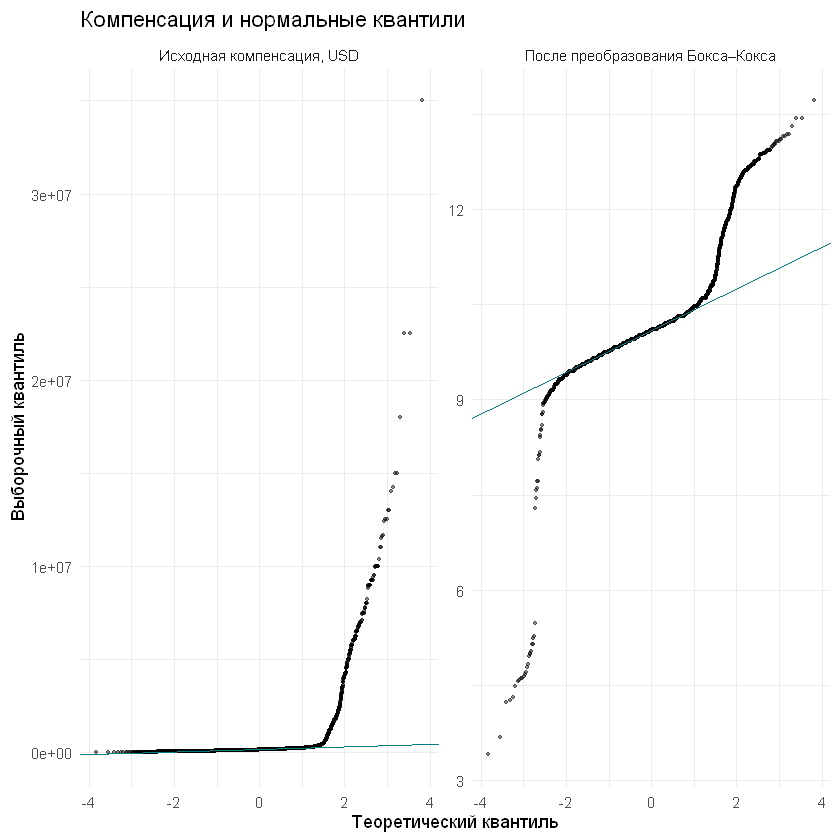

In [9]:
qq_values <- bind_rows(
  data.frame(values = income$income, scale = "Исходная компенсация, USD"),
  data.frame(values = transformed_income, scale = "После преобразования Бокса–Кокса")
)
ggplot(qq_values, aes(sample = values)) +
  stat_qq(alpha = 0.45, size = 0.7) +
  stat_qq_line(colour = "#007C83") +
  facet_wrap(vars(scale), scales = "free_y") +
  labs(
    title = "Компенсация и нормальные квантили",
    x = "Теоретический квантиль", y = "Выборочный квантиль"
  ) +
  theme_minimal()

## 5. Восстановление пропусков и выбор метода

Целевая переменная — логарифм годовой компенсации. Предикторы — общий, профессиональный и трудовой стаж. Сравниваются множественная импутация методом predictive mean matching (`mice`) и bootstrap EM (`Amelia`). Медиана наблюдённых компенсаций служит базовым методом сравнения.

Для оценки случайно скрываются 10% известных компенсаций. Прогноз берётся как медиана пяти заполнений, качество измеряется средней абсолютной ошибкой в логарифмической шкале. Метод множественной импутации с меньшей ошибкой повторно оценивается на исходной таблице с пропусками. Для итогового набора сохраняется одна из реализаций. Для анализа коэффициентов объединяются все пять результатов по правилам Рубина через `mitools`.

In [10]:
imputation_data <- data.frame(
  log_income = log(prepared$ConvertedCompYearly),
  coding_years = prepared$YearsCode,
  professional_years = prepared$YearsCodePro,
  work_years = prepared$WorkExp
)

# Заполнить числовую таблицу методом PMM или bootstrap EM.
# data — data.frame, method — имя метода, seed — целое число.
# Возвращает пять полных таблиц с одинаковым порядком строк.
impute <- function(data, method, seed) {
  if (method == "mice") {
    model <- mice::mice(data, m = 5, method = "pmm", maxit = 5, seed = seed, printFlag = FALSE)
    return(as.list(mice::complete(model, action = "all")))
  }

  set.seed(seed)
  bounds <- rbind(
    c(2, 0, 51),
    c(3, 0, 51),
    c(4, 0, 100)
  )
  model <- Amelia::amelia(
    data, m = 5, bounds = bounds, empri = 0.01 * nrow(data), p2s = 0
  )
  if (model$code != 1L) {
    stop("Amelia: ", model$message)
  }
  model$imputations
}

set.seed(704)
known <- which(!is.na(imputation_data$log_income))
holdout <- sample(known, size = floor(0.1 * length(known)))
masked <- imputation_data
masked$log_income[holdout] <- NA_real_
truth <- imputation_data$log_income[holdout]

methods <- c("mice", "Amelia")
holdout_error <- vapply(methods, function(method) {
  estimates <- impute(masked, method, 704L)
  predictions <- vapply(estimates, function(data) data$log_income[holdout], numeric(length(holdout)))
  mean(abs(apply(predictions, 1L, median) - truth))
}, numeric(1))

baseline <- mean(abs(median(masked$log_income, na.rm = TRUE) - truth))
chosen <- names(which.min(holdout_error))
data.frame(
  method = c("Медиана", names(holdout_error)),
  masked_responses = length(holdout),
  mae_log_income = c(baseline, unname(holdout_error))
)
data.frame(chosen_multiple_imputation = chosen)

method,masked_responses,mae_log_income
<chr>,<int>,<dbl>
Медиана,757,0.5207153
mice,757,0.5631808
Amelia,757,0.7263195


chosen_multiple_imputation
<chr>
mice


In [11]:
completions <- impute(imputation_data, chosen, 705L)
analyses <- with(
  mitools::imputationList(completions),
  lm(log_income ~ professional_years + coding_years + work_years)
)
combined <- mitools::MIcombine(analyses)
summary(combined)

finished <- completions[[1L]]
observed_income <- !is.na(imputation_data$log_income)
stopifnot(
  all(vapply(completions, function(data) !anyNA(data), logical(1))),
  identical(finished$log_income[observed_income], imputation_data$log_income[observed_income])
)

Multiple imputation results:
      with(mitools::imputationList(completions), lm(log_income ~ professional_years + 
    coding_years + work_years))
      MIcombine.default(analyses)
                       results          se       (lower       upper) missInfo
(Intercept)        11.88343019 0.023990131 11.834782017 11.932078360     37 %
professional_years  0.01889382 0.004250658  0.010240681  0.027546961     39 %
coding_years        0.00407415 0.002799872 -0.001499156  0.009647456     24 %
work_years         -0.01248597 0.003192982 -0.019188541 -0.005783408     52 %


## 6. Качество данных до и после обработки

Сравниваем число пропусков, непригодных значений, анкет без идентификатора и повторных идентификаторов. Заполнение выполнено для четырёх числовых признаков. Категориальные пропуски остаются видимыми. Кандидаты в выбросы сохраняются, потому что редкая или высокая компенсация сама по себе не свидетельствует об ошибке. Сравнение на скрытых известных значениях оценивает восстановление случайно удалённых ответов. Механизм пропуска реальных ответов может отличаться. На исходных данных медиана дала наименьшую абсолютную ошибку для отдельной компенсации. Среди множественных методов меньшую ошибку дал PMM. Его использовали для объединения оценок регрессии с учётом неопределённости заполнения.

In [12]:
quality <- data.frame(
  metric = c(
    "Анкеты", "Анкеты без идентификатора", "Повторные идентификаторы",
    "Пропуски в четырёх числовых полях", "Непригодные числовые значения",
    "Недоступные ответы в трёх категориальных полях"
  ),
  before = c(
    nrow(source_group), sum(is.na(source_group$ResponseId)),
    sum(duplicated(na.omit(source_group$ResponseId))),
    sum(is.na(source_group[names(invalid)])), sum(lengths(lapply(invalid, which))),
    sum(is.na(source_group[c("Age", "EdLevel", "RemoteWork")])) +
      sum(source_group$Age == "Prefer not to say", na.rm = TRUE)
  ),
  after = c(
    nrow(prepared), sum(is.na(prepared$ResponseId)), sum(duplicated(prepared$ResponseId)),
    sum(is.na(finished)), sum(!is.finite(as.matrix(finished)) & !is.na(as.matrix(finished))),
    sum(is.na(prepared[c("Age", "EdLevel", "RemoteWork")]))
  )
)
quality

data.frame(
  observed_compensation = sum(observed_income),
  filled_compensation = sum(!observed_income),
  median_observed_usd = median(prepared$ConvertedCompYearly, na.rm = TRUE),
  median_completed_usd = median(exp(finished$log_income))
)

metric,before,after
<chr>,<int>,<int>
Анкеты,9133,9133
Анкеты без идентификатора,0,0
Повторные идентификаторы,0,0
Пропуски в четырёх числовых полях,4717,0
Непригодные числовые значения,0,0
Недоступные ответы в трёх категориальных полях,140,140


observed_compensation,filled_compensation,median_observed_usd,median_completed_usd
<int>,<int>,<dbl>,<dbl>
7577,1556,146000,145000
